### Problem 13 : The Data Re-uploading Classifier - one qubit is enough

Two notebooks ago our two-qubit VQC hit a wall at about 85% on the moons dataset, and Problem 12
told us that throwing more qubits at it is not just useless but actively harmful. So what *is* the
fix?

**Feed the data into the circuit more than once.**

That one idea, introduced by Pérez-Salinas et al. (2020), is called **data re-uploading**, and the
headline result is remarkable : a **single qubit** with data re-uploading is a *universal*
classifier. In this notebook one qubit will comfortably beat the two-qubit model from Problem 10.

📄 Paper : https://quantum-journal.org/papers/q-2020-02-06-226/

**TASK :** Build a single-qubit re-uploading classifier for the moons dataset and compare it,
head to head, against the Problem 10 result.

#### Why encoding once is a bottleneck

Think about what a standard VQC computes. The circuit is

∣0⟩ → **S(x)** → **W(θ)** → measure

where S(x) is the feature map and W(θ) is the trainable part. Whatever W does, the data only ever
entered through S. Write the output as a function of x and you get a **truncated Fourier series**
whose available frequencies are fixed entirely by S. With one RY(x) rotation per feature, you get
frequency 1 and nothing else - roughly a sine wave. No amount of training on W can create a
frequency that the encoding never put there.

#### What re-uploading changes

Interleave them instead :

∣0⟩ → **S(x)** → W(θ₁) → **S(x)** → W(θ₂) → **S(x)** → W(θ₃) → … → measure

Every extra upload adds new frequencies to the Fourier series, so an L-layer re-uploading circuit
can express a far richer function of x. The direct classical analogy is a neural network with
**skip connections feeding the input into every hidden layer**.

Our layer will be a little richer than a bare re-upload : each layer applies

**RY(w₁·x₀ + w₂) · RZ(w₃·x₁ + w₄) · RY(w₅)**

so each feature gets its own trainable **scale** (a weight) and **shift** (a bias) before being
loaded, plus a free rotation. Five parameters per layer, on one qubit.

In [1]:
import pennylane as qml
from pennylane import numpy as np

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

In [2]:
# Step 1: The exact same dataset as Problem 10 - this has to be a fair fight
X, y = make_moons(n_samples=200, noise=0.15, random_state=42)
X = StandardScaler().fit_transform(X)
y = 2 * y - 1

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_train = np.array(X_train, requires_grad=False)
y_train = np.array(y_train, requires_grad=False)

print("Training points:", X_train.shape, " Test points:", X_test.shape)

Training points: (140, 2)  Test points: (60, 2)


In [3]:
# Step 2: The single-qubit re-uploading circuit
n_layers = 5

dev = qml.device("default.qubit", wires=1)      # ONE qubit. That is the whole quantum computer.


@qml.qnode(dev)
def circuit(weights, x):
    for layer in range(n_layers):
        # the data is re-injected in EVERY layer, with its own trainable scale and shift
        qml.RY(weights[layer, 0] * x[0] + weights[layer, 1], wires=0)
        qml.RZ(weights[layer, 2] * x[1] + weights[layer, 3], wires=0)
        qml.RY(weights[layer, 4], wires=0)      # a free rotation, no data
    return qml.expval(qml.PauliZ(0))

In [4]:
print(qml.draw(circuit)(np.ones((n_layers, 5)), X_train[0]))
print()
print("Qubits              :", dev.wires)
print("Trainable parameters:", n_layers * 5, "+ 1 bias")

0: ──RY(0.11)──RZ(2.36)──RY(1.00)──RY(0.11)──RZ(2.36)──RY(1.00)──RY(0.11)──RZ(2.36)──RY(1.00) ···

0: ··· ──RY(0.11)──RZ(2.36)──RY(1.00)──RY(0.11)──RZ(2.36)──RY(1.00)─┤  <Z>

Qubits              : Wires([0])
Trainable parameters: 25 + 1 bias


In [5]:
# Step 3: Model, loss, accuracy - unchanged from Problem 10
def model(weights, bias, X):
    return np.array([circuit(weights, x) for x in X]) + bias


def cost(weights, bias, X, y):
    return np.mean((model(weights, bias, X) - y) ** 2)


def accuracy(weights, bias, X, y):
    return np.mean(np.sign(model(weights, bias, X)) == y)

> Note the initialisation below : `np.random.normal(0, 1.0, ...)`, i.e. *wide*. In Problem 12 we
> learned to start near the identity to dodge barren plateaus - but that advice is about **random
> deep entangling circuits on many qubits**. Here we have one qubit and a highly structured ansatz,
> there is no plateau to fall into, and the scale weights genuinely need to be free to grow large so
> they can create high frequencies. Context matters more than rules of thumb.

In [6]:
# Step 4: Train
np.random.seed(1)
weights = np.random.normal(0, 1.0, (n_layers, 5), requires_grad=True)
bias = np.array(0.0, requires_grad=True)

opt = qml.AdamOptimizer(stepsize=0.15)
batch_size = 25
n_steps = 120

for step in range(n_steps):
    batch = np.random.randint(0, len(X_train), batch_size)
    weights, bias, _, _ = opt.step(cost, weights, bias, X_train[batch], y_train[batch])

    if (step + 1) % 20 == 0:
        c = cost(weights, bias, X_train, y_train)
        a = accuracy(weights, bias, X_train, y_train)
        print(f"Step {step + 1:3d} | loss {c:.4f} | train accuracy {a:.3f}")

Step  20 | loss 0.2564 | train accuracy 0.936


Step  40 | loss 0.1653 | train accuracy 0.950


Step  60 | loss 0.1219 | train accuracy 0.986


Step  80 | loss 0.0969 | train accuracy 0.979


Step 100 | loss 0.0888 | train accuracy 0.986


Step 120 | loss 0.1284 | train accuracy 0.979


In [7]:
# Step 5: Evaluate and compare against Problem 10
train_acc = float(accuracy(weights, bias, X_train, y_train))
test_acc = float(accuracy(weights, bias, X_test, y_test))

print(f"Training accuracy: {train_acc:.3f}")
print(f"Test accuracy    : {test_acc:.3f}")
print()
print("--------------------------------------------------------")
print(" model                                qubits   test acc ")
print("--------------------------------------------------------")
print(" Problem 10  VQC, encode once            2       ~0.85   ")
print(f" Problem 13  data re-uploading           1       {test_acc:.2f}    ")
print("--------------------------------------------------------")

Training accuracy: 0.979
Test accuracy    : 0.967

--------------------------------------------------------
 model                                qubits   test acc 
--------------------------------------------------------
 Problem 10  VQC, encode once            2       ~0.85   
 Problem 13  data re-uploading           1       0.97    
--------------------------------------------------------


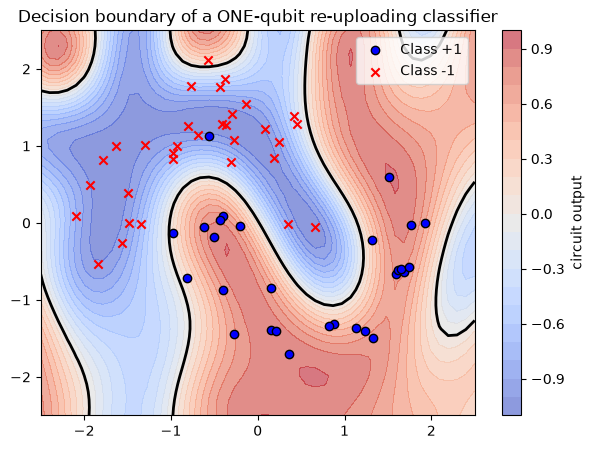

In [8]:
# The decision boundary - compare this shape with the one from Problem 10
xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 50), np.linspace(-2.5, 2.5, 50))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = model(weights, bias, grid).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, levels=20, cmap='coolwarm', alpha=0.6)
plt.colorbar(label='circuit output')
plt.contour(xx, yy, zz, levels=[0], colors='k', linewidths=2)
plt.scatter(X_test[y_test == 1][:, 0], X_test[y_test == 1][:, 1], c='b', marker='o', edgecolor='k', label='Class +1')
plt.scatter(X_test[y_test == -1][:, 0], X_test[y_test == -1][:, 1], c='r', marker='x', label='Class -1')
plt.title("Decision boundary of a ONE-qubit re-uploading classifier")
plt.legend(); plt.show()

#### OUTCOME :

Around **96-97%** test accuracy, from a circuit with a single qubit and 26 parameters - against
~85% from the two-qubit, 25-parameter model in Problem 10. Look at the boundary : it curves and
wraps around the moons instead of slicing gently through them.

Nothing about the *hardware* got bigger. We did not add a qubit, we did not add entanglement - there
is nothing to entangle with. What changed is that the data now enters the circuit five times
instead of once, so the function the circuit can express is far richer.

#### The lesson that ties Problems 10-13 together

- **Problem 10** : a VQC trains, but plateaus.
- **Problem 11** : a different framework and a different optimizer plateau at the same place - so
  it is the model, not the training.
- **Problem 12** : making the model bigger makes things *worse*, not better.
- **Problem 13** : making the model **better structured** fixes it, on one qubit.

In quantum machine learning, **how you encode the data is the model**. Ansatz design and qubit
count are secondary. If your quantum model underperforms, look at the feature map first.

#### Key Takeaways :
- Encoding data once fixes the frequency spectrum your circuit can express.
- Re-uploading the data in every layer enriches that spectrum - the quantum analogue of skip
  connections.
- A single-qubit re-uploading circuit is a **universal classifier**.
- Structure beats scale.

#### TASK :
1. Sweep `n_layers` from 1 to 8 and plot test accuracy against layer count. Where does it saturate?
2. Remove the re-uploading : keep 5 layers but only inject the data in the first one (drop the
   `* x[...]` terms from layers 1-4). The accuracy should fall straight back to the Problem 10
   level. This is the cleanest possible proof of what is doing the work.
3. Extend the circuit to 2 qubits with re-uploading on both, plus a CNOT per layer. Does
   entanglement buy you anything on this dataset - and is the extra cost worth it?